In [3]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, log_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the saved model bundle
model_path = Path("../models/futiq_best_model.joblib")
model_bundle = joblib.load(model_path)
final_model = model_bundle["model"]
label_encoder = model_bundle["label_encoder"]
feature_columns = model_bundle["feature_columns"]
print("Selected model:", model_bundle["model_name"])
print("Features expected:", len(feature_columns))

Selected model: LightGBM
Features expected: 14


In [4]:
data_dir = Path("../data/processed")
X_test = pd.read_csv(data_dir / "X_test.csv")
y_test = pd.read_csv(data_dir / "y_test.csv").squeeze("columns")

# Keep exactly the features and order used during training
X_test = X_test[feature_columns]

# Convert target labels using the saved encoder
y_test_encoded = label_encoder.transform(y_test)

print("Test features:", X_test.shape)
print("Test target:", y_test.shape)

Test features: (836, 14)
Test target: (836,)


In [6]:
y_pred= final_model.predict(X_test)
y_prob=final_model.predict_proba(X_test)
#Convert numerical predictions to H, D, A
y_pred_labels=label_encoder.inverse_transform(y_pred)
print("Actual Results: ", y_test.head(5).tolist())
print("Predictions: ", y_pred[:5].tolist())

Actual Results:  ['AW', 'HW', 'HW', 'HW', 'HW']
Predictions:  [0, 2, 2, 0, 1]


In [8]:
test_results = {
    "Accuracy": accuracy_score(y_test_encoded, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test_encoded, y_pred),
    "Precision (Macro)": precision_score(y_test_encoded,y_pred, average="macro", zero_division=0),
    "Recall (Macro)": recall_score(y_test_encoded,y_pred,average="macro",zero_division=0),
    "F1 (Macro)": f1_score(y_test_encoded,y_pred,average="macro",zero_division=0),

    "Log Loss": log_loss(y_test_encoded,y_prob,labels=np.arange(len(label_encoder.classes_)))
}
test_results_df=pd.DataFrame(
    test_results.items(),
    columns=["Metric", "Score"]
)
test_results_df.round(4)

,Metric,Score
0,Accuracy,0.4211
1,Balanced Accuracy,0.3866
2,Precision (Macro),0.3861
3,Recall (Macro),0.3866
4,F1 (Macro),0.3842
5,Log Loss,1.1703


In [12]:
y_train=pd.read_csv(data_dir/"y_train.csv").squeeze("columns")
majority_class=y_train.mode()[0]
baseline_pred=np.full(len(y_test), majority_class)
baseline_accuracy=accuracy_score(y_test, baseline_pred)
baseline_f1=f1_score(y_test, baseline_pred, average="macro", zero_division=0)
print("Baseline Outcome: ", majority_class)
print("Baseline Accuracy: ", round(baseline_accuracy, 4))
print("Baseline Macro F1: ", round(baseline_f1, 4))
print("FutIQ Accuracy: ", round(test_results["Accuracy"], 4))
print("FutIQ F1: ", round(test_results["F1 (Macro)"], 4))

Baseline Outcome:  HW
Baseline Accuracy:  0.4199
Baseline Macro F1:  0.1971
FutIQ Accuracy:  0.4211
FutIQ F1:  0.3842


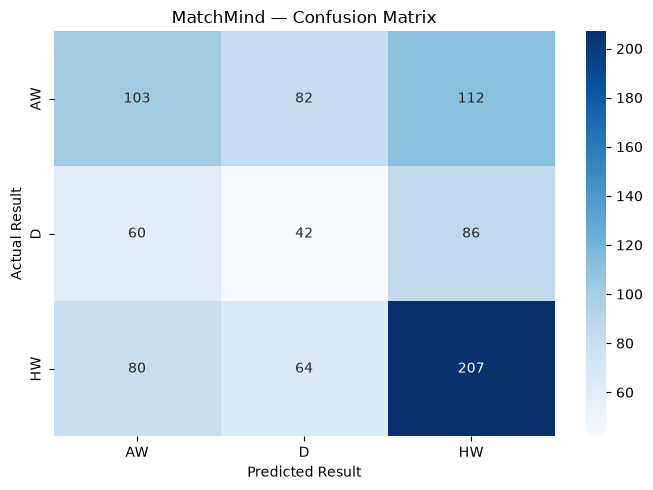

In [ ]:
class_labels=label_encoder.classes_
cm=confusion_matrix(y_test_encoded, y_pred, labels=np.arange(len(class_labels)))
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.title("MatchMind — Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()

In [14]:
report = classification_report(
    y_test_encoded,
    y_pred,
    labels=np.arange(len(class_labels)),
    target_names=class_labels,
    output_dict=True,
    zero_division=0
)

class_report = pd.DataFrame(report).T

class_report.round(4)

,precision,recall,f1-score,support
AW,0.4239,0.3468,0.3815,297.0000
D,0.2234,0.2234,0.2234,188.0000
HW,0.5111,0.5897,0.5476,351.0000
accuracy,0.4211,0.4211,0.4211,0.4211
macro avg,0.3861,0.3866,0.3842,836.0000
weighted avg,0.4154,0.4211,0.4157,836.0000


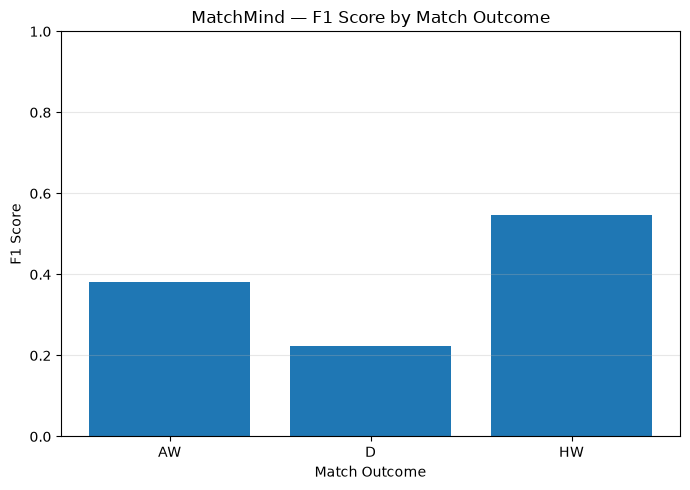

In [15]:
class_f1 = class_report.loc[
    ["AW", "D", "HW"],
    "f1-score"
]

plt.figure(figsize=(7, 5))

plt.bar(class_f1.index, class_f1.values)

plt.title("MatchMind — F1 Score by Match Outcome")
plt.xlabel("Match Outcome")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()


In [17]:
prediction_report = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred_labels,
    "Correct": (
        y_test.reset_index(drop=True).to_numpy()
        == y_pred_labels
    )
})
# Add one probability column for each class
for index, outcome in enumerate(class_labels):
    prediction_report[f"Probability_{outcome}"] = y_prob[:, index]
prediction_report.head(20)
#Inspect incorrect predictions
incorrect_pred=prediction_report[
    prediction_report["Correct"]==False
]
print("Total Incorrect Predictions: ", len(incorrect_pred))
incorrect_pred.head(20)

Total Incorrect Predictions:  484


,Actual,Predicted,Correct,Probability_AW,Probability_D,Probability_HW
3,HW,AW,False,0.528206,0.126066,0.345729
4,HW,D,False,0.116832,0.567821,0.315347
6,AW,HW,False,0.040351,0.013308,0.946341
10,HW,AW,False,0.818708,0.047179,0.134114
15,AW,HW,False,0.321757,0.215842,0.462401
16,AW,HW,False,0.168070,0.314544,0.517385
17,AW,D,False,0.420471,0.494549,0.084980
18,AW,HW,False,0.329683,0.314349,0.355967
23,HW,AW,False,0.650058,0.045849,0.304093
24,HW,D,False,0.102526,0.500941,0.396533


In [18]:
output_dir = Path("../outputs/reports")
output_dir.mkdir(parents=True, exist_ok=True)
# Save evaluation metrics
test_results_df.to_csv(output_dir / "final_test_metrics.csv", index=False)

# Save class-wise report
class_report.to_csv(output_dir / "class_wise_performance.csv")

# Save predictions
prediction_report.to_csv(output_dir / "test_predictions.csv", index=False)

# Save confusion matrix
cm_df = pd.DataFrame(cm, index=[f"Actual_{label}" for label in class_labels],
    columns=[f"Predicted_{label}" for label in class_labels])

cm_df.to_csv(output_dir / "confusion_matrix.csv")

print("Evaluation reports saved.")

Evaluation reports saved.
